Technological Institute of the Philippines | Quezon City - Computer Engineering
--- | ---
Course Code: | CPE 027
Code Title: | Digital Signal Processing and Application
1st Semester | AY 2026-2027
<u>**Laboratory Activity 4** | **ADC, DAC, and Aliasing Signals**
**Name** | Adrian Justin Bulambao<br> Christian Dale Pateña <br> Maureen Santiago
**Section** | CPE41S1
**Date Performed**: | August 7, 2026
**Date Submitted**: | August 7, 2026
**Instructor**: | Engr. Ji Han Gang

<hr>


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. Develop a program to extract the wav file, snsd.wav, from the drive.


In [ ]:
import os

print(os.path.exists(r"/content/drive/MyDrive/CPE 027 - DSP Files/LAB 4/snsd.wav"))

True


2. Capture and plot the first 10 seconds of the audio signals and listen to it. As you plot the audio signal using a program, you are basically transforming the signal into digital signal. Notice the sampling frequency used to sample the audio signal, does it follow the sampling theorem?


Sampling Frequency: 44100 Hz
Duration: 201.04 seconds


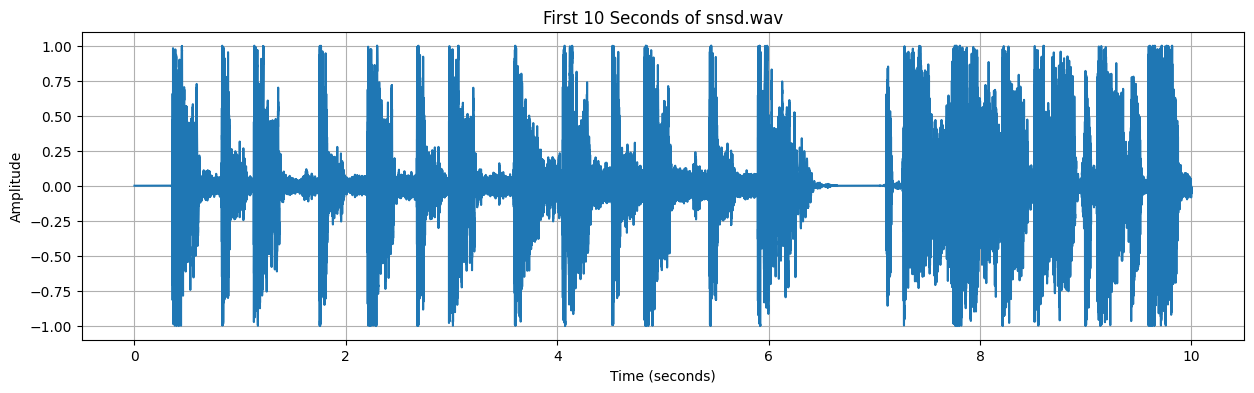

In [ ]:
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio
audio, sr = librosa.load(r"/content/drive/MyDrive/CPE 027 - DSP Files/LAB 4/snsd.wav", sr=None)

print(f"Sampling Frequency: {sr} Hz")
print(f"Duration: {len(audio)/sr:.2f} seconds")
audio_10s = audio[:10 * sr]
time = [i / sr for i in range(len(audio_10s))]
plt.figure(figsize=(15, 4))
plt.plot(time, audio_10s)
plt.title("First 10 Seconds of snsd.wav")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

The sampling theorem is 44,100hz, it does follow the sampling theorem as it is twice of the hearing rate of humans which is 20,000hz.

3. To mimic the analog filter, filter the captured signal with the use of low-pass Bessel filter using scipy.signal library and plot it. Provide the cutoff frequency.


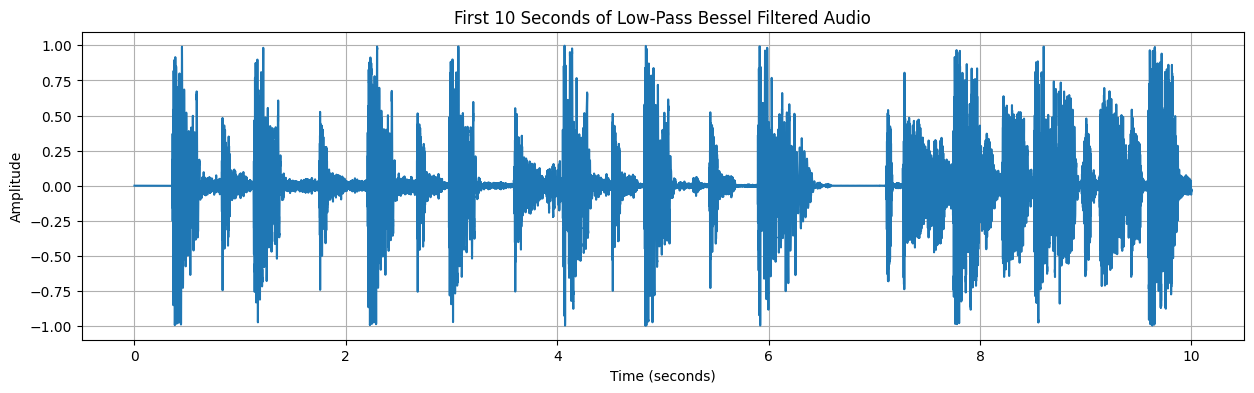

Cutoff Frequency: 2000 Hz


In [ ]:
import numpy as np
from scipy.signal import bessel, filtfilt

fc = 2000
order = 4

b, a = bessel(order, fc, btype='low', fs=sr)

# Apply the filter
filtered_audio = filtfilt(b, a, audio)

# Extract the first 10 seconds
filtered_10s = filtered_audio[:10 * sr]
time = np.arange(len(filtered_10s)) / sr

# Plot the filtered signal
plt.figure(figsize=(15,4))
plt.plot(time, filtered_10s)
plt.title("First 10 Seconds of Low-Pass Bessel Filtered Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

print(f"Cutoff Frequency: {fc} Hz")

In [ ]:
from IPython.display import Audio, display

print("Original Audio (First 10 Seconds)")
display(Audio(audio_10s, rate=sr))

print("Filtered Audio (First 10 Seconds)")
display(Audio(filtered_10s, rate=sr))

Original Audio (First 10 Seconds)


Filtered Audio (First 10 Seconds)


4. Using impulse train, perform 2 multirate techniques - one interpolation and the other decimation - and plot the 2 created sampled signals. Provide the number of samples for each technique.


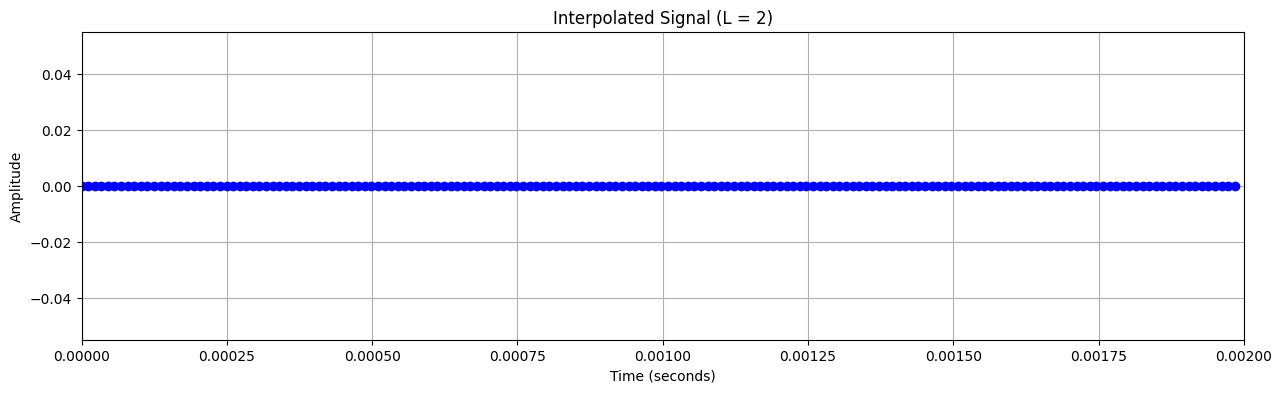

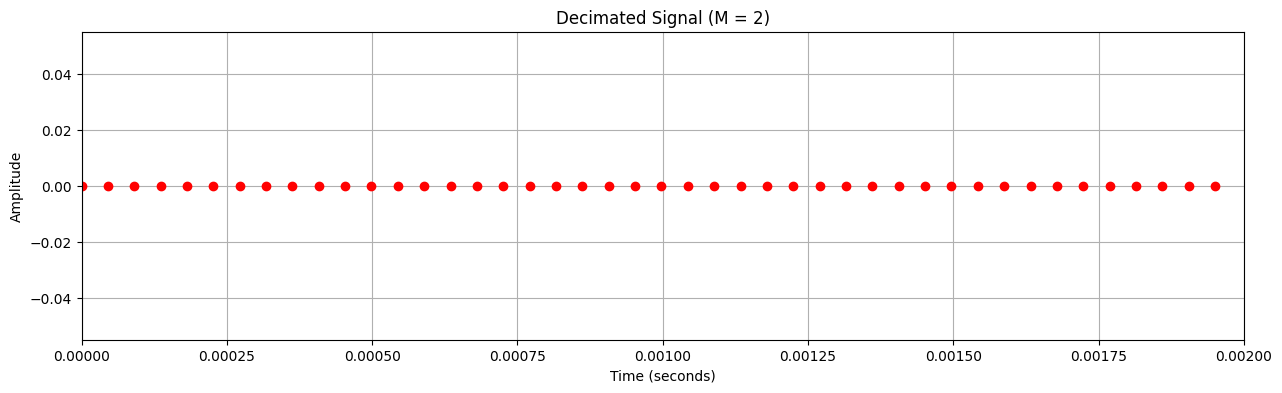

In [ ]:
# Plot duration (2 ms)
duration = 0.002

interp_samples = int(duration * sr * L)
decim_samples = int(duration * (sr / M))

time_interp = np.arange(interp_samples) / (sr * L)
time_decim = np.arange(decim_samples) / (sr / M)

# Interpolated Signal
plt.figure(figsize=(15,4))
plt.stem(time_interp, interpolated[:interp_samples],
         linefmt='b-', markerfmt='bo', basefmt=' ')
plt.title("Interpolated Signal (L = 2)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, duration)
plt.grid(True)
plt.show()

# Decimated Signal
plt.figure(figsize=(15,4))
plt.stem(time_decim, decimated[:decim_samples],
         linefmt='r-', markerfmt='ro', basefmt=' ')
plt.title("Decimated Signal (M = 2)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, duration)
plt.grid(True)
plt.show()